In [49]:
import numpy as np
from IPython.display import display, Math
from sympy import latex
import matplotlib.pyplot as plt

from sympy import (
    init_printing,
    Derivative,
    diff,
    simplify,
    symbols,
    exp,
    Abs,
    ln,
    sqrt,
    solveset,
    S,
    Interval,
    hessian,
    DiracDelta,
)
from sympy.calculus.util import continuous_domain
from sympy.core.relational import Eq, GreaterThan, StrictGreaterThan
from sympy import lambdify
from sympy import factor

init_printing()

In [216]:
N = 10_000
left, right = -1.0, 2.0
given_interval = Interval(left, right)
order = 2
x_grid = np.random.uniform(left, right, N)

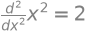

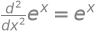

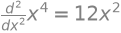

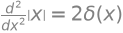

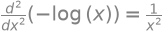

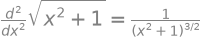

In [217]:
x = symbols("x", real=True)
f1 = x**2
f2 = exp(x)
f3 = x**4
f4 = Abs(x)
f5 = -ln(x)
f6 = sqrt(1 + x**2)
functions_sympy = [f1, f2, f3, f4, f5, f6]
derivatives = [diff(f, x, order) for f in functions_sympy]

for f, d in zip(functions_sympy, derivatives):
    display(Eq(Derivative(f, x, 2), simplify(d)))

In [218]:
for f, d in zip(functions_sympy, derivatives):
    # operand = StrictGreaterThan
    if d.has(DiracDelta):
        domain = S.Reals - {0}
        operand = GreaterThan
        sol = solveset(operand(d, 0), x, domain=domain)

    else:
        domain = S.Reals
        operand = StrictGreaterThan
        sol = solveset(operand(d, 0), x, domain=domain)

    display(
        Math(f"{latex(operand(Derivative(f, x, 2), 0))}, \\quad x \\in {latex(sol)}")
    )

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [219]:
def latex_sci(x):
    if x == 0:
        return "0"

    exponent = int(np.floor(np.log10(abs(x))))
    mantissa = x / 10**exponent

    return f"{mantissa:.3f}\\times10^{{{exponent}}}"

In [231]:
np.random.seed(4)
lam = np.random.rand(N*100)
errors = {}

for f_sympy in functions_sympy:
    domain = continuous_domain(f_sympy, x, S.Reals).intersect(given_interval)
    # print(f"Domain of f(x) = {latex(f_sympy)}: {latex(domain)}")
    start = float(domain.start)
    end = float(domain.end)
    x1, x2 = np.random.uniform(start, end, (2, N*100))

    f = lambdify(x, f_sympy, "numpy")
    expr = f(lam * x1 + (1.0 - lam) * x2) - lam * f(x1) - (1.0 - lam) * f(x2)
    max_error = np.max(expr)
    errors[f_sympy] = max_error

    display(
        Math(f"f(x) = {latex(f_sympy)},\\quad\\varepsilon = {latex_sci(max_error)}")
    )
    print(
        f"{'Неравенство численно выполнено' if np.all(expr <= 1e-12) else 'Неравенство численно не выполнено'}"
    )


<IPython.core.display.Math object>

Неравенство численно выполнено


<IPython.core.display.Math object>

Неравенство численно выполнено


<IPython.core.display.Math object>

...

Неравенство численно выполнено


<IPython.core.display.Math object>

Неравенство численно выполнено


<IPython.core.display.Math object>

Неравенство численно выполнено


In [232]:
display(
    Math(
        f"\\varepsilon_{{\\text{{max}}}} = {latex_sci(max(errors.values()))},"
        f"\\quad \\text{{ учитывая |x|}}"
    )
)

<IPython.core.display.Math object>

In [233]:
errors[Abs(x)] = -np.inf
display(
    Math(
        f"\\varepsilon_{{\\text{{max}}}} = {latex_sci(max(errors.values()))},"
        f"\\quad \\text{{ без учета |x|}}"
    )
)

<IPython.core.display.Math object>

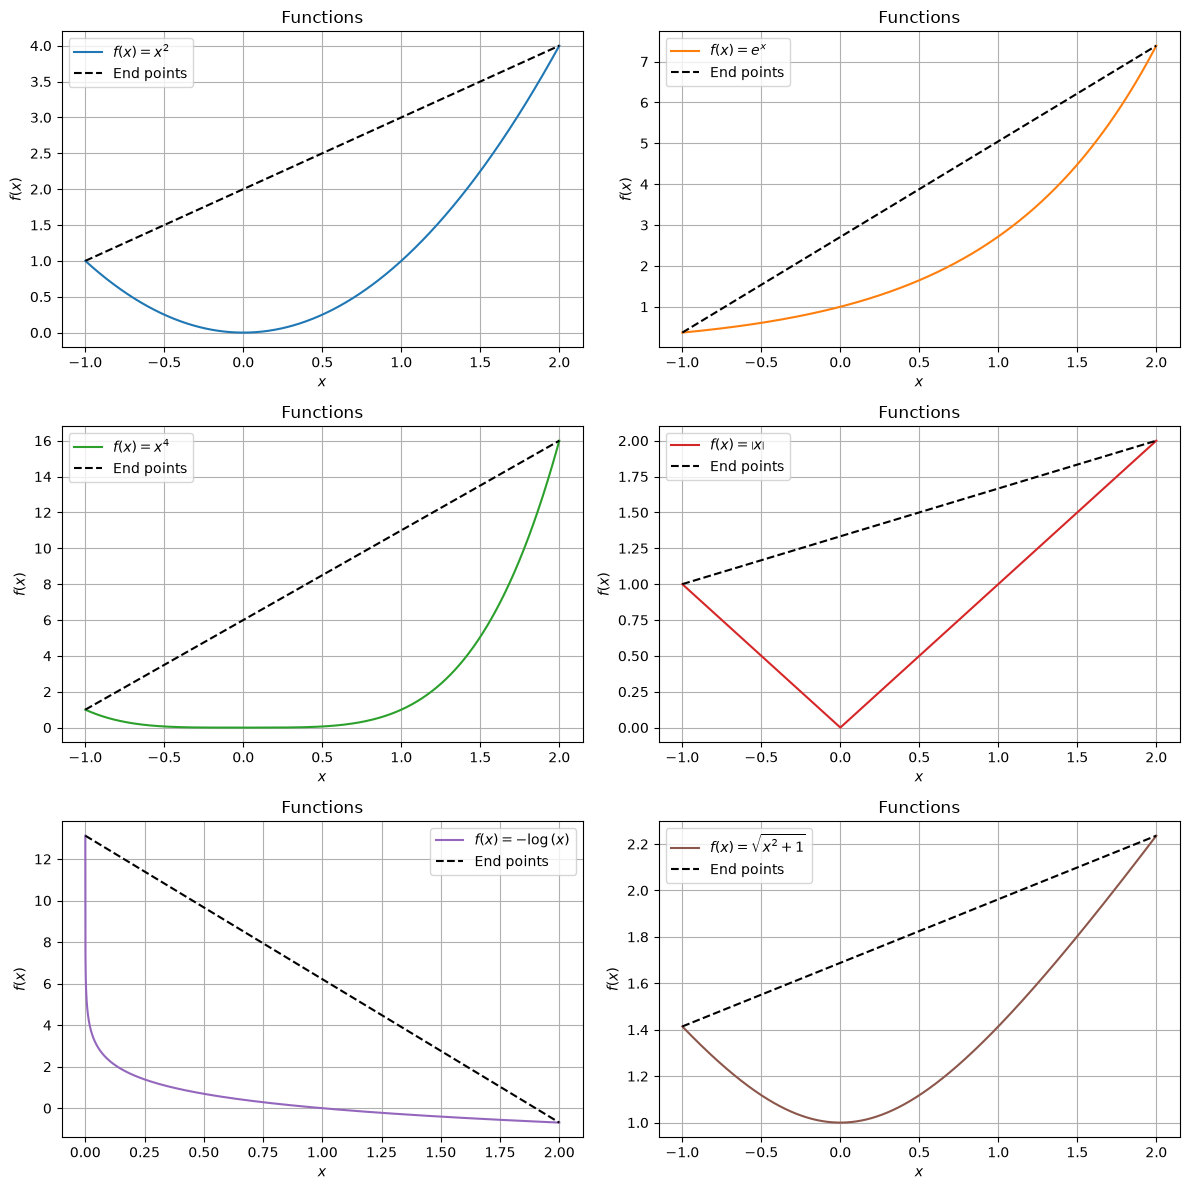

In [224]:
x_grid_plot = np.linspace(left, right, N)
cmap = plt.cm.tab10

fig, ax = plt.subplots(3, 2, figsize=(12, 12))

for i, f_sympy in enumerate(functions_sympy):
    f = lambdify(x, f_sympy, "numpy")

    domain = continuous_domain(f_sympy, x, S.Reals).intersect(given_interval)
    eps = 1e-6 * (domain.end - domain.start)

    start = domain.start if not domain.left_open else domain.start + eps
    end = domain.end if not domain.right_open else domain.end - eps

    x_plot = np.linspace(float(start), float(end), N)
    left_plot, right_plot = x_plot[0], x_plot[-1]

    a = ax[i // 2, i % 2]
    a.plot(x_plot, f(x_plot), label=f"$f(x) = {latex(f_sympy)}$", c=cmap(i))
    a.plot(
        [left_plot, right_plot],
        [f(left_plot), f(right_plot)],
        "k--",
        label="End points",
    )

    a.grid()
    a.set_title("Functions")
    a.set_xlabel("$x$")
    a.set_ylabel("$f(x)$")
    a.legend()

plt.tight_layout()
plt.show()


$$
\text{Критерий выпуклости:}\qquad
f''(x)\geq0,\ \forall x\in X
$$

$$
\text{Критерий сильной выпуклости:}\qquad
\exists \theta>0:
\quad
f''(x)\geq2\theta,\ \forall x\in X
$$


$$
\begin{array}{c|c|c}
f(x)&f''(x)&\text{вывод}\\
\hline
x^2&
2\gt0&
\text{сильно выпуклая}
\\[2mm]

e^x&
e^x>0&
\text{строго выпуклая, не сильно}
\\[2mm]

x^4&
12x^2\geq0&
\text{строго выпуклая, не сильно}
\\[2mm]

|x|&
2\delta(x)=0&
\text{выпуклая}
\\[2mm]

-\ln x&
\dfrac1{x^2}>0&
\text{строго выпуклая, не сильно}
\\[3mm]

\sqrt{1+x^2}&
\dfrac1{(1+x^2)^{3/2}}>0&
\text{строго выпуклая, не сильно}
\end{array}
$$



# Задание 1.2

In [225]:
x1, x2 = symbols("x_1 x_2", real=True)

g1 = x1**2 + x2**2
g2 = x1**2 / x2  # x2 > 0
g3 = sqrt(1 + x1**2 + x2**2)

functions_sympy_2d = [g1, g2, g3]
hessians = {}

for g in functions_sympy_2d:
    H = simplify(hessian(g, (x1, x2)))
    hessians[g] = H

    display(Math(f"\\Delta \\left({latex(g)}\\right) = {latex(H)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [226]:
def sylvester_test(H):
    minors = []

    for i in range(H.rows):
        minors.append(H[: i + 1, : i + 1].det())

    return [factor(m) for m in minors]


# from sympy.assumptions import ask, Q


for i, (g, H) in enumerate(hessians.items(), 1):
    minors = sylvester_test(H)
    # display([ask(Q.nonnegative(m)) for m in minors])
    display(Math(f"\\text{{Миноры гессиана }} H_{i}"))

    for j, m in enumerate(minors, 1):
        display(Math(f"A^{{{j}}}_{{{j}}} = {latex(m)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [227]:
eigenvalues = {}

for i, (g, H) in enumerate(hessians.items(), 1):
    display(Math(f"\\text{{Сводка собственных значений для }} H_{i}:"))

    eigenvalues[g] = []
    for j, eig in enumerate(H.eigenvects(), 1):
        lam = eig[0]
        eigenvalues[g].append(lam)
        alg_mult = eig[1]
        geom_mult = len(eig[2])
        # lam = simplify(lam)

        display(
            Math(
                f"\\lambda_{j} = {latex(lam)}, \\quad АК = {latex(alg_mult)}, \\quad ГК = {latex(geom_mult)}"
            )
        )


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

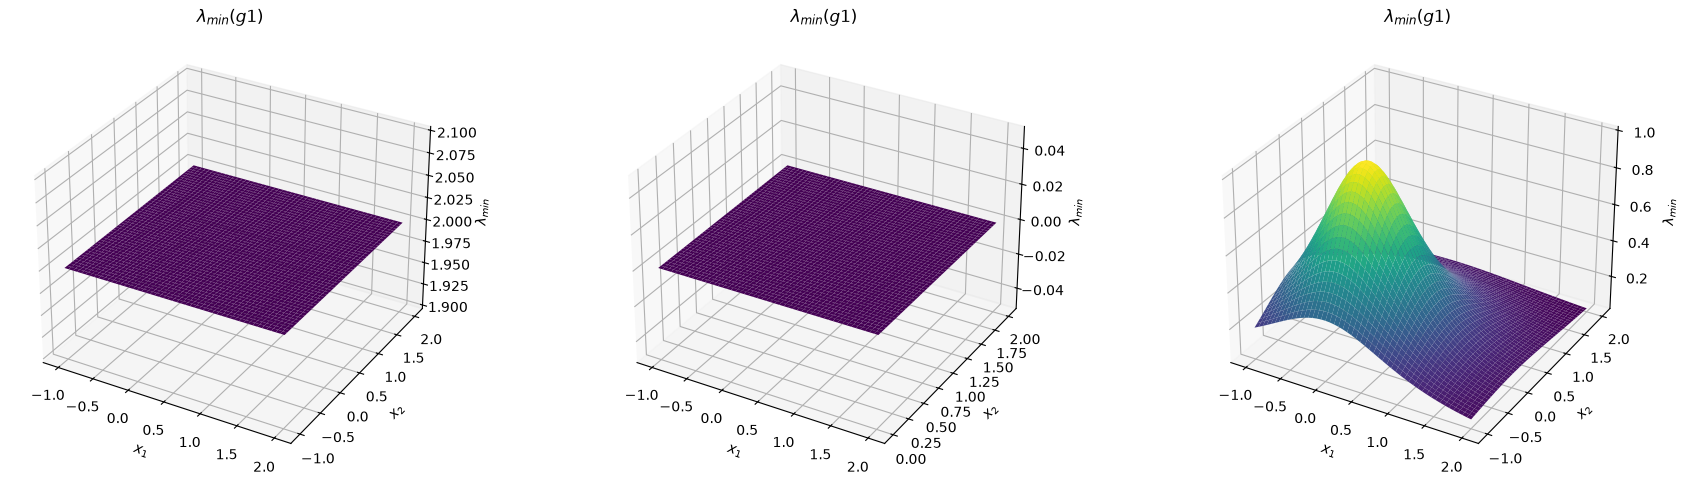

In [228]:
fig = plt.figure(figsize=(18, 5))

for i, (g, eigs) in enumerate(eigenvalues.items(), 1):
    Y, X = np.mgrid[left:right:1000j, left:right:1000j]

    if g.has(1 / x2):
        Y, X = np.mgrid[1e-2:right:1000j, left:right:1000j]

    lam_min = eigs[0]
    lam_min_func = lambdify((x1, x2), lam_min, "numpy")
    Z = lam_min_func(X, Y) * np.ones_like(X)

    ax = fig.add_subplot(int(f"13{i}"), projection="3d")
    ax.plot_surface(X, Y, Z, cmap="viridis")
    ax.set_title("$\\lambda_{min}(g1)$")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_zlabel("$\\lambda_{min}$")

plt.tight_layout()
plt.show()


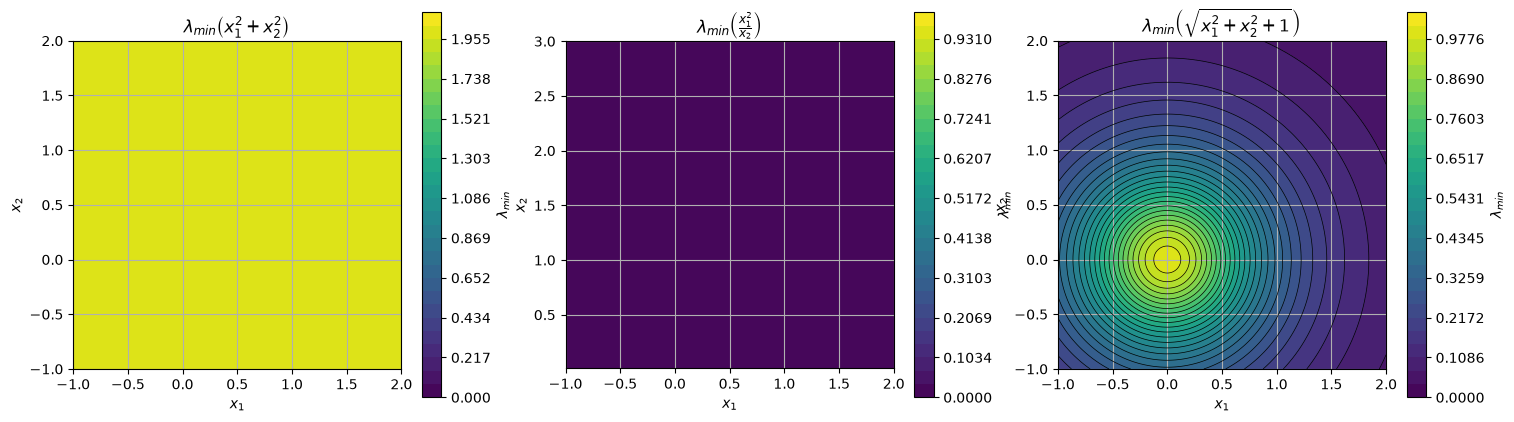

In [229]:
eps = 1e-12
n_levels = 30


def make_grid(g):
    if g.has(1 / x2):
        return np.mgrid[1e-2 : right + abs(left) : 500j, left:right:500j]
    return np.mgrid[left:right:500j, left:right:500j]


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (g, eigs) in zip(axes, eigenvalues.items()):
    Y, X = make_grid(g)
    lam_min = eigs[0]
    Z = lambdify((x1, x2), lam_min, "numpy")(X, Y) * np.ones_like(X)

    z_max = np.max(Z)
    upper = z_max * 1.05

    if upper < eps:
        upper = 1.0

    levels = np.linspace(0.0, upper, n_levels)
    filled = ax.contourf(X, Y, Z, levels=levels, cmap="viridis")

    # Контуры строим только для непостоянной функции
    if np.ptp(Z) > eps:
        ax.contour(X, Y, Z, levels=levels, colors="black", linewidths=0.5)

    ax.set_title(f"$\\lambda_{{min}}\\left({latex(g)}\\right)$")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")
    ax.grid()

    fig.colorbar(
        filled,
        ax=ax,
        label="$\\lambda_{min}$",
    )

plt.show()

## Вывод о выпуклости функций

Для дважды дифференцируемой функции:

$$
f \text{ сильно выпукла} \iff \lambda_{\min}(H(x))\geq \mu>0
$$

По графику $\lambda_{\min}(H(x_1,x_2))$ можно определить характер выпуклости.

### $g_1(x_1,x_2)=x_1^2+x_2^2$


Минимальное собственное значение постоянно и ограничено снизу:

$$
\lambda_{\min}\geq2
$$

Следовательно, функция является:

$$
\boxed{\text{сильно выпуклой}}
$$


### $g_2(x_1,x_2)=\frac{x_1^2}{x_2},\quad x_2>0$

$$
\lambda_{\min}=0
$$

Гессиан неотрицательно определён, но нет положительной нижней границы $\mu$.

Следовательно:

$$
\boxed{\text{выпуклая, но не строго и не сильно выпуклая}}
$$


### $g_3(x_1,x_2)=\sqrt{1+x_1^2+x_2^2}$

Во всей области:

$$
\lambda_{\min}(H_3)>0
$$

Следовательно, функция строго выпуклая.

Однако:

$$
\lambda_{\min}(H_3)\rightarrow0
\quad \text{при}\quad x_1^2+x_2^2\rightarrow\infty
$$

поэтому невозможно выбрать $\mu>0$ для всей области.

Итог:

$$
\boxed{\text{строго, но не сильно выпуклая}}
$$